# Hyperparameter sweep analysis

Each algorithm was tuned on `Cologne-v1` with a random search over 50 hyperparameter
combinations (`COMBO_ID`), 3 seeds each. This notebook

1. checks that the sweep is complete,
2. ranks the combinations by their mean best test return over the 3 seeds,
3. shows the hyperparameters and learning curves of the top combinations,
4. compares the best combination of each algorithm with the heuristic,
5. shows how sensitive the return is to each swept hyperparameter, and
6. shows the distribution of the combinations' returns per algorithm (CDF).

The rank-1 combination of each algorithm is the one used for the final runs
(`experiments/config/final_runs/`). The sweep results are read from
`tuning_results.parquet`, released on Zenodo; the first cell downloads it if it is missing.

In [1]:
# The sweep and heuristic results, downloaded from Zenodo if they are not here yet
from common import baseline_values, data_file

TUNING_RESULTS_FILE = data_file("tuning_results.parquet")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

METRIC = "test_returned_episode_returns"
TOP_N = 5

# Expected sweep size per algorithm, used by the completeness checks
NUM_COMBOS = 50
NUM_SEEDS_PER_COMBO = 3

# Expected return of the segment-based heuristic on Cologne-v1 (the sweep's map), the
# reference of the comparison plots
HEURISTIC_BASELINE = baseline_values()["Cologne-v1"]

RUN_KEYS = ["alg", "combo_id", "seed"]

## Load the sweep

`tuning_results.parquet` holds the training history of every sweep run: one row per logged
update, with the run's algorithm, `COMBO_ID`, seed and hyperparameters. A hyperparameter that
an algorithm does not use is empty. `runs_df` keeps one row per run with its best and final
test return and its last logged `env_step`.

In [3]:
tuning = pd.read_parquet(TUNING_RESULTS_FILE).rename(
    columns={"algorithm": "alg", "COMBO_ID": "combo_id", "SEED": "seed"}
)
tuning = tuning.sort_values([*RUN_KEYS, "env_step"], ignore_index=True)

# Hyperparameter columns. REWARD_STANDARDIZATION and SCALE_CLIP_EPS are switches that are
# the same across the sweep, so they are not treated as hyperparameters.
HISTORY_COLUMNS = {"env_step", METRIC, "returned_episode_returns"}
HYPERPARAMS = [
    c
    for c in tuning.columns
    if c
    not in {*RUN_KEYS, *HISTORY_COLUMNS, "REWARD_STANDARDIZATION", "SCALE_CLIP_EPS"}
]

test_curves = tuning.dropna(subset=[METRIC])
runs_df = (
    test_curves.groupby(RUN_KEYS)[METRIC]
    .agg(best_test_return="max", final_test_return="last")
    .join(tuning.groupby(RUN_KEYS)["env_step"].max().rename("last_env_step"))
    .reset_index()
)
# Hyperparameters are the same on every row of a run
run_hyperparams = tuning.groupby(RUN_KEYS)[HYPERPARAMS].first().reset_index()

print(f"{len(runs_df)} runs, {len(tuning):,} logged updates")
runs_df.head()

750 runs, 5,832,360 logged updates


,alg,combo_id,seed,best_test_return,final_test_return,last_env_step
0,ippo_rnn,C0001,101,-1.223934e+10,-1.240101e+10,49971200.0
1,ippo_rnn,C0001,102,-1.317764e+10,-1.317764e+10,49971200.0
2,ippo_rnn,C0001,103,-1.318157e+10,-1.350790e+10,49971200.0
3,ippo_rnn,C0026,101,-1.481802e+10,-1.504807e+10,49987584.0
4,ippo_rnn,C0026,102,-1.548936e+10,-1.565361e+10,49987584.0


## Sweep completeness

Every algorithm should have `NUM_COMBOS` combinations with `NUM_SEEDS_PER_COMBO` seeds each.
A run is **complete** when it trained for its full budget: the training scripts run
`NUM_UPDATES = TOTAL_TIMESTEPS // NUM_STEPS // NUM_ENVS` updates and log `env_step` after each
one, so the last logged `env_step` of a complete run is exactly
`NUM_UPDATES × NUM_ENVS × NUM_STEPS`. A run cut short (for example by a cluster time limit)
logs less.

The table summarises this per algorithm; `truncated` lists the runs that are not complete.
A check after it makes sure that no two combinations of an algorithm have the same
hyperparameters.

In [4]:
cfg = run_hyperparams.set_index(RUN_KEYS)
num_updates = cfg["TOTAL_TIMESTEPS"] // cfg["NUM_STEPS"] // cfg["NUM_ENVS"]
expected_final_step = num_updates * cfg["NUM_ENVS"] * cfg["NUM_STEPS"]
runs_df["completed_frac"] = (
    runs_df.set_index(RUN_KEYS)["last_env_step"] / expected_final_step
).to_numpy()
runs_df["complete"] = runs_df["completed_frac"] == 1.0

seeds_per_combo = runs_df.groupby(["alg", "combo_id"]).size().groupby("alg")
by_alg = runs_df.groupby("alg")
completeness = pd.DataFrame(
    {
        "combos": by_alg["combo_id"].nunique(),
        "seeds/combo": seeds_per_combo.min().astype(str)
        + "–"
        + seeds_per_combo.max().astype(str),
        "runs": by_alg.size(),
        "complete runs": by_alg["complete"].sum(),
        # combo/seed (fraction of training reached) of every run that is not complete
        "truncated": pd.Series(
            {
                alg: ", ".join(
                    f"{r.combo_id}/{r.seed} ({r.completed_frac:.0%})"
                    for r in g[~g["complete"]].itertuples()
                )
                for alg, g in by_alg
            }
        ),
    }
)
completeness["as expected"] = np.where(
    (completeness["combos"] == NUM_COMBOS)
    & (completeness["complete runs"] == NUM_COMBOS * NUM_SEEDS_PER_COMBO),
    "✓",
    "✗",
)
completeness.rename_axis("algorithm")

,combos,seeds/combo,runs,complete runs,truncated,as expected
algorithm,,,,,,
ippo_rnn,50,3–3,150,150,,✓
mappo_rnn,50,3–3,150,150,,✓
pqn_rnn,50,3–3,150,150,,✓
qmix_rnn,50,3–3,150,150,,✓
vdn_rnn,50,3–3,150,150,,✓


In [5]:
# One hyperparameter signature per combination; two combinations of the same algorithm with
# the same signature would be a duplicate point of the sweep.
combo_hyperparams = run_hyperparams.groupby(["alg", "combo_id"])[HYPERPARAMS].first()
# The hyperparameters an algorithm uses, as a dict per combination
signatures = pd.Series(
    {combo: row.dropna().to_dict() for combo, row in combo_hyperparams.iterrows()},
    name="signature",
).rename_axis(["alg", "combo_id"])
keys = signatures.map(lambda hp: str(sorted(hp.items()))).reset_index()
duplicates = keys[keys.duplicated(["alg", "signature"], keep=False)]

if duplicates.empty:
    print("Every combination has unique hyperparameters within its algorithm.")
else:
    print("Combinations with identical hyperparameters within the same algorithm:")
    display(duplicates[["alg", "combo_id"]])

Every combination has unique hyperparameters within its algorithm.


## Rank the combinations

Each combination is scored by `best_test_return` (the maximum of a run's test-return
curve) averaged over its seeds. `top_combos_by_alg` holds the top `TOP_N` combinations of
each algorithm, best first; rank 1 is the one used for the final runs.

In [6]:
combo_df = (
    runs_df.groupby(["alg", "combo_id"])
    .agg(
        mean_best_test_return=("best_test_return", "mean"),
        std_best_test_return=("best_test_return", "std"),
        n_seeds=("seed", "count"),
    )
    .reset_index()
    .sort_values("mean_best_test_return", ascending=False)
)
combo_df["rank"] = combo_df.groupby("alg").cumcount() + 1

top_combos_by_alg = {
    alg: alg_df[alg_df["rank"] <= TOP_N].set_index("rank")
    for alg, alg_df in combo_df.groupby("alg")
}

for alg, alg_df in top_combos_by_alg.items():
    print(f"=== {alg} ===")
    display(alg_df.drop(columns="alg"))

=== ippo_rnn ===


,combo_id,mean_best_test_return,std_best_test_return,n_seeds
rank,,,,
1,C0054,-1.206616e+10,3.109713e+08,3
2,C0071,-1.251727e+10,3.321004e+08,3
3,C0040,-1.256005e+10,5.406422e+08,3
4,C0048,-1.263881e+10,5.490651e+08,3
5,C0001,-1.286618e+10,5.428699e+08,3


=== mappo_rnn ===


,combo_id,mean_best_test_return,std_best_test_return,n_seeds
rank,,,,
1,C0022,-1.099480e+10,2.519597e+08,3
2,C0018,-1.101067e+10,1.514991e+08,3
3,C0012,-1.102521e+10,1.107648e+08,3
4,C0040,-1.118152e+10,1.070293e+08,3
5,C0026,-1.124025e+10,2.109485e+08,3


=== pqn_rnn ===


,combo_id,mean_best_test_return,std_best_test_return,n_seeds
rank,,,,
1,C0031,-1.161422e+10,2.124735e+08,3
2,C0043,-1.172530e+10,3.731790e+08,3
3,C0045,-1.196876e+10,6.866859e+08,3
4,C0022,-1.205459e+10,5.232405e+08,3
5,C0040,-1.240277e+10,1.129420e+08,3


=== qmix_rnn ===


,combo_id,mean_best_test_return,std_best_test_return,n_seeds
rank,,,,
1,C0007,-1.059447e+10,1.120409e+08,3
2,C0044,-1.076019e+10,2.932049e+08,3
3,C0045,-1.080437e+10,2.861556e+08,3
4,C0047,-1.084161e+10,2.914032e+08,3
5,C0008,-1.085309e+10,1.789541e+08,3


=== vdn_rnn ===


,combo_id,mean_best_test_return,std_best_test_return,n_seeds
rank,,,,
1,C0011,-1.076756e+10,3.128686e+08,3
2,C0003,-1.093443e+10,1.171601e+08,3
3,C0023,-1.099102e+10,9.282641e+07,3
4,C0004,-1.101038e+10,1.687059e+08,3
5,C0043,-1.133319e+10,1.856885e+08,3


## Hyperparameters of the top combinations

One table per algorithm, indexed by rank (1 = best) and `combo_id`. Hyperparameters the
algorithm does not use are left out.

In [7]:
hyperparams_by_alg = {}
for alg, alg_combos in top_combos_by_alg.items():
    alg_hp = signatures.loc[alg]
    rows = [
        {"rank": rank, "combo_id": combo_id, **dict(alg_hp[combo_id])}
        for rank, combo_id in alg_combos["combo_id"].items()
    ]
    hyperparams_by_alg[alg] = pd.DataFrame(rows).set_index(["rank", "combo_id"])

for alg, alg_hp_df in hyperparams_by_alg.items():
    print(f"=== {alg} ===")
    display(alg_hp_df)

=== ippo_rnn ===


,,ACTIVATION,ANNEAL_LR,CLIP_EPS,ENT_COEF,FC_DIM_SIZE,GAE_LAMBDA,GRU_HIDDEN_DIM,LR,MAX_GRAD_NORM,NUM_ENVS,NUM_MINIBATCHES,NUM_STEPS,TOTAL_TIMESTEPS,UPDATE_EPOCHS,VF_COEF
rank,combo_id,,,,,,,,,,,,,,,
1,C0054,relu,0.0,0.1,0.001,128.0,0.98,128.0,0.00010,0.5,64,4.0,128,50000000,8.0,0.5
2,C0071,relu,0.0,0.2,0.001,128.0,0.98,128.0,0.00010,0.5,128,4.0,256,50000000,8.0,0.5
3,C0040,relu,0.0,0.1,0.001,128.0,0.98,128.0,0.00010,0.5,64,4.0,256,50000000,8.0,0.5
4,C0048,relu,0.0,0.2,0.001,128.0,0.98,128.0,0.00010,0.5,64,4.0,256,50000000,8.0,0.5
5,C0001,relu,0.0,0.2,0.001,128.0,0.98,128.0,0.00025,0.5,128,4.0,256,50000000,4.0,0.5


=== mappo_rnn ===


,,ACTIVATION,ANNEAL_LR,CLIP_EPS,ENT_COEF,FC_DIM_SIZE,GAE_LAMBDA,GRU_HIDDEN_DIM,LR,MAX_GRAD_NORM,NUM_ENVS,NUM_MINIBATCHES,NUM_STEPS,TOTAL_TIMESTEPS,UPDATE_EPOCHS,VF_COEF
rank,combo_id,,,,,,,,,,,,,,,
1,C0022,relu,0.0,0.1,0.001,128.0,0.95,128.0,0.00025,0.5,64,2.0,256,50000000,8.0,0.5
2,C0018,relu,0.0,0.1,0.001,128.0,0.95,128.0,0.00050,0.5,128,2.0,128,50000000,4.0,0.5
3,C0012,relu,0.0,0.1,0.001,128.0,0.95,128.0,0.00050,0.5,64,4.0,256,50000000,4.0,0.5
4,C0040,relu,0.0,0.1,0.001,128.0,0.98,128.0,0.00010,0.5,64,4.0,256,50000000,8.0,0.5
5,C0026,relu,0.0,0.1,0.001,128.0,0.95,128.0,0.00010,0.5,64,4.0,256,50000000,8.0,0.5


=== pqn_rnn ===


,,EPS_DECAY,EPS_FINISH,EPS_START,HIDDEN_SIZE,LAMBDA,LR,LR_LINEAR_DECAY,MAX_GRAD_NORM,MEMORY_WINDOW,NORM_INPUT,NORM_TYPE,NUM_ENVS,NUM_EPOCHS,NUM_LAYERS,NUM_MINIBATCHES,NUM_STEPS,REW_SCALE,TOTAL_TIMESTEPS
rank,combo_id,,,,,,,,,,,,,,,,,,
1,C0031,0.2,0.00,1.0,128.0,0.95,0.0001,0.0,0.5,4.0,1.0,batch_norm,128,4.0,2.0,16.0,51,1.000000e-09,50000000
2,C0043,0.2,0.00,1.0,128.0,0.95,0.0001,0.0,0.5,4.0,1.0,layer_norm,128,4.0,2.0,16.0,51,1.000000e-09,50000000
3,C0045,0.2,0.01,1.0,128.0,0.85,0.0001,0.0,0.5,4.0,1.0,batch_norm,128,4.0,2.0,16.0,51,1.000000e-09,50000000
4,C0022,0.1,0.01,1.0,128.0,0.85,0.0001,0.0,0.5,4.0,1.0,batch_norm,128,4.0,2.0,16.0,51,1.000000e-09,50000000
5,C0040,0.1,0.01,1.0,128.0,0.65,0.0001,0.0,0.5,4.0,1.0,batch_norm,128,4.0,2.0,16.0,51,1.000000e-09,50000000


=== qmix_rnn ===


,,BUFFER_BATCH_SIZE,BUFFER_SIZE,EPS_DECAY,EPS_FINISH,EPS_START,HIDDEN_SIZE,LEARNING_STARTS,LR,LR_LINEAR_DECAY,MAX_GRAD_NORM,MIXER_EMBEDDING_DIM,MIXER_HYPERNET_HIDDEN_DIM,MIXER_INIT_SCALE,NUM_ENVS,NUM_EPOCHS,NUM_STEPS,REW_SCALE,TARGET_UPDATE_INTERVAL,TAU,TOTAL_TIMESTEPS
rank,combo_id,,,,,,,,,,,,,,,,,,,,
1,C0007,32.0,5000.0,0.1,0.0,1.0,128.0,10000.0,0.0010,0.0,10.0,32.0,128.0,0.001,32,8.0,51,1.000000e-09,200.0,1.0,20000000
2,C0044,32.0,5000.0,0.2,0.0,1.0,128.0,10000.0,0.0005,0.0,10.0,32.0,128.0,0.001,32,8.0,51,1.000000e-09,10.0,1.0,20000000
3,C0045,32.0,5000.0,0.2,0.0,1.0,512.0,10000.0,0.0001,0.0,10.0,32.0,128.0,0.001,32,8.0,51,1.000000e-09,10.0,1.0,20000000
4,C0047,32.0,5000.0,0.1,0.0,1.0,128.0,10000.0,0.0005,0.0,10.0,32.0,128.0,0.001,32,8.0,51,1.000000e-09,10.0,1.0,20000000
5,C0008,32.0,5000.0,0.2,0.0,1.0,128.0,10000.0,0.0010,0.0,10.0,64.0,256.0,0.001,32,8.0,51,1.000000e-09,200.0,1.0,20000000


=== vdn_rnn ===


,,BUFFER_BATCH_SIZE,BUFFER_SIZE,EPS_DECAY,EPS_FINISH,EPS_START,HIDDEN_SIZE,LEARNING_STARTS,LR,LR_LINEAR_DECAY,MAX_GRAD_NORM,NUM_ENVS,NUM_EPOCHS,NUM_STEPS,REW_SCALE,TARGET_UPDATE_INTERVAL,TAU,TOTAL_TIMESTEPS
rank,combo_id,,,,,,,,,,,,,,,,,
1,C0011,32.0,5000.0,0.2,0.0,1.0,512.0,10000.0,0.0001,0.0,10.0,32,8.0,51,1.000000e-09,10.0,1.0,20000000
2,C0003,32.0,5000.0,0.2,0.0,1.0,128.0,10000.0,0.0005,0.0,10.0,32,8.0,51,1.000000e-09,200.0,1.0,20000000
3,C0023,32.0,5000.0,0.2,0.0,1.0,128.0,10000.0,0.0005,0.0,10.0,32,8.0,51,1.000000e-09,10.0,1.0,20000000
4,C0004,32.0,5000.0,0.2,0.0,1.0,128.0,10000.0,0.0010,0.0,10.0,32,8.0,51,1.000000e-09,200.0,1.0,20000000
5,C0043,32.0,5000.0,0.1,0.0,1.0,128.0,10000.0,0.0005,0.0,10.0,32,8.0,51,1.000000e-09,10.0,1.0,20000000


## Learning curves of the top combinations

One row per algorithm and one column per rank (best combination on the left), with one line
per seed. Axes are shared within a row, so the combinations of an algorithm can be compared
directly. The dashed line is the heuristic.

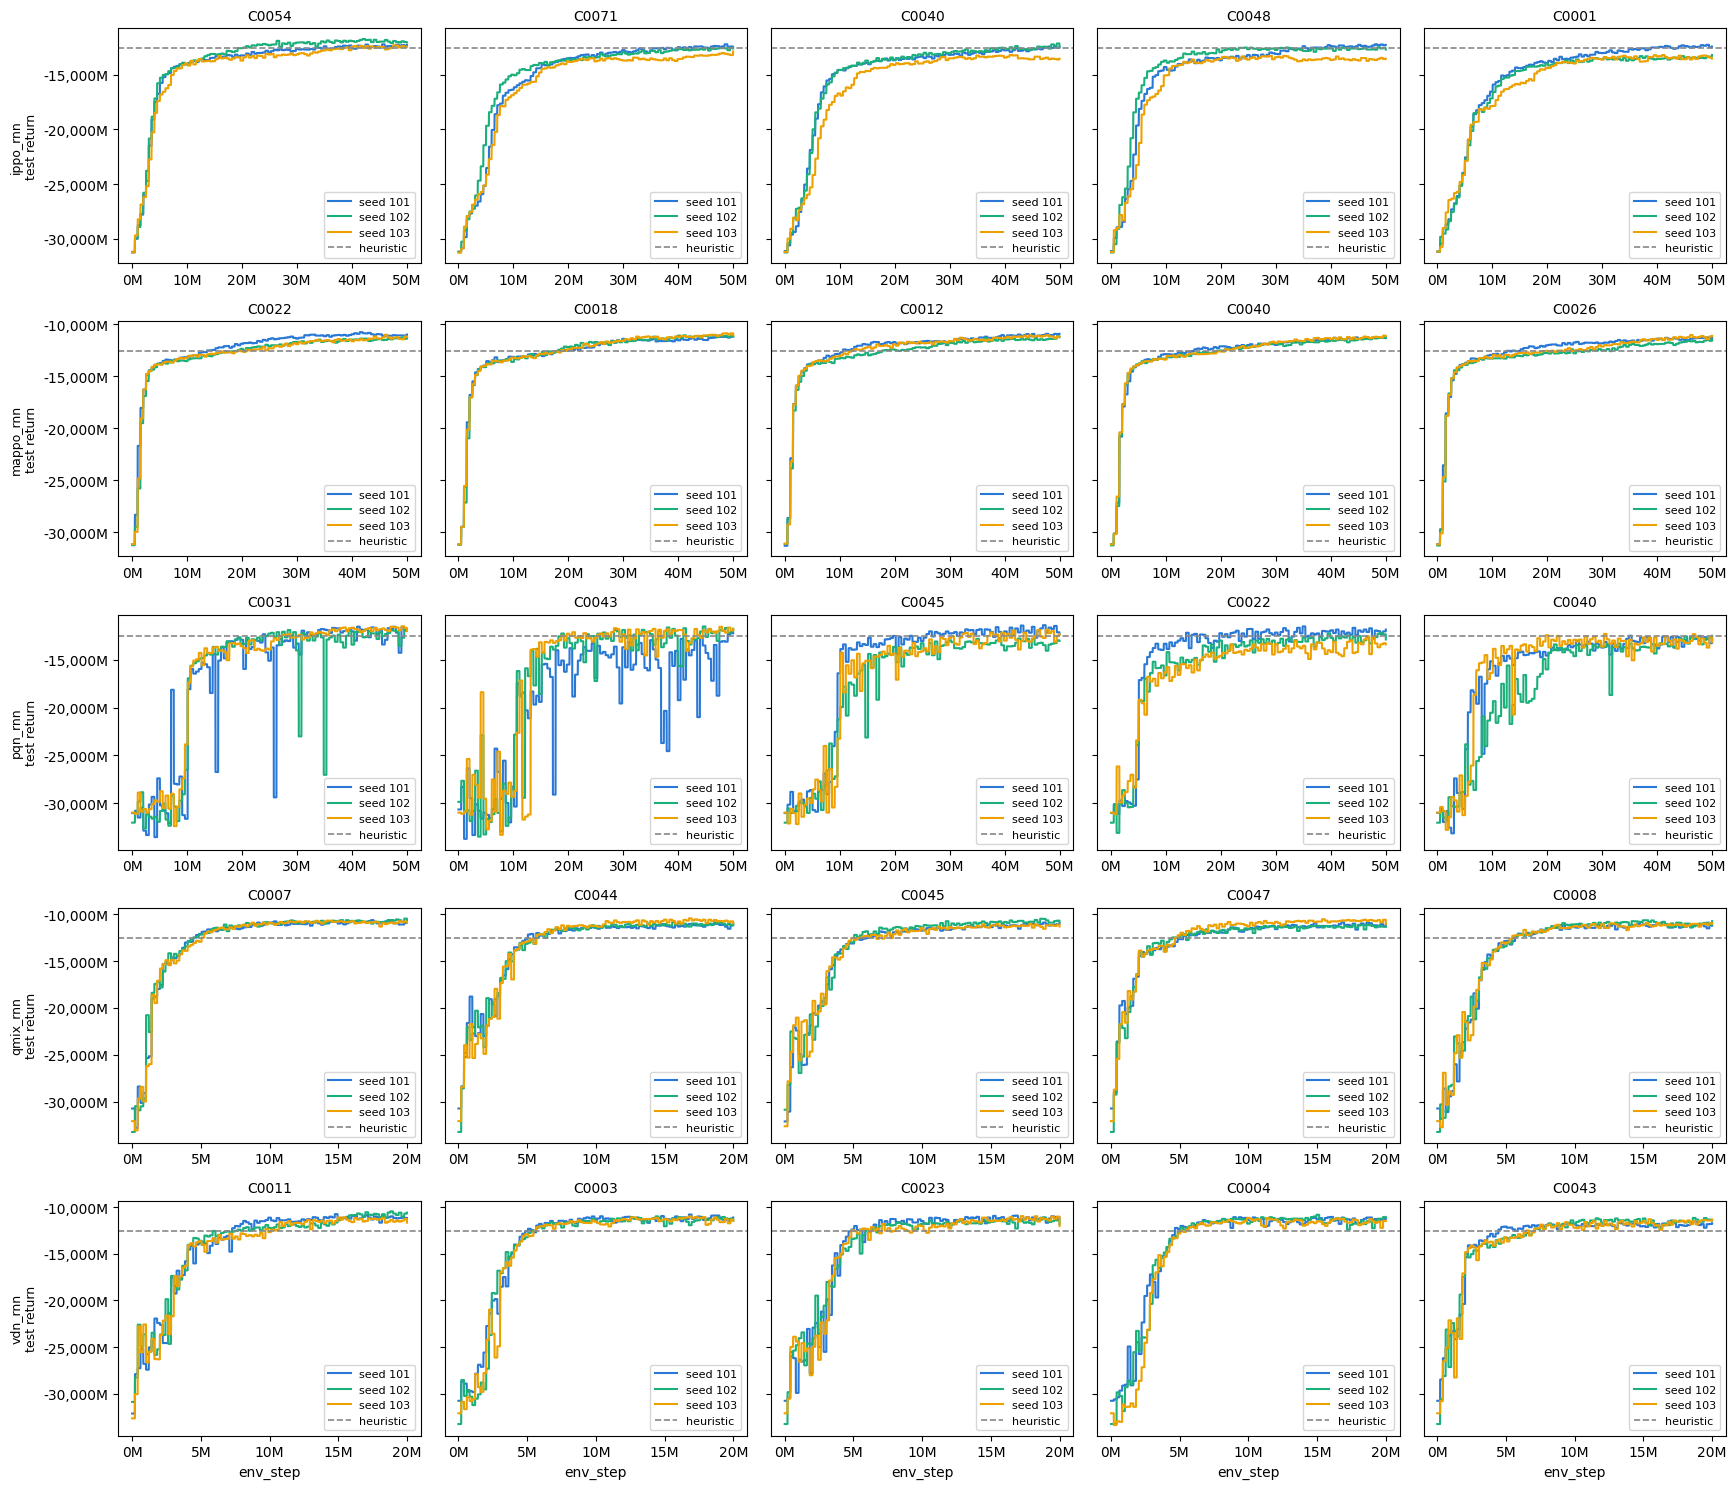

In [8]:
# Fixed-order categorical palette (one hue per seed slot)
SEED_COLORS = ["#2a78d6", "#1baf7a", "#eda100"]
BASELINE_COLOR = "#888888"

millions_formatter = FuncFormatter(lambda v, _: f"{v / 1e6:,.0f}M")
curves_by_combo = dict(list(test_curves.groupby(["alg", "combo_id"])))


def plot_combo_learning_curve(alg, combo_id, ax):
    combo_curves = curves_by_combo[(alg, combo_id)]
    for seed_idx, (seed, curve) in enumerate(combo_curves.groupby("seed")):
        ax.plot(
            curve["env_step"],
            curve[METRIC],
            color=SEED_COLORS[seed_idx % len(SEED_COLORS)],
            linewidth=1.5,
            label=f"seed {seed}",
        )
    ax.axhline(
        HEURISTIC_BASELINE,
        color=BASELINE_COLOR,
        linestyle="--",
        linewidth=1.2,
        label="heuristic",
    )
    ax.yaxis.set_major_formatter(millions_formatter)
    ax.xaxis.set_major_formatter(millions_formatter)
    ax.set_title(combo_id, fontsize=10)
    ax.legend(fontsize=8)


algs = list(top_combos_by_alg)
fig, axes = plt.subplots(
    len(algs),
    TOP_N,
    figsize=(3.5 * TOP_N, 3.0 * len(algs)),
    squeeze=False,
    sharex="row",
    sharey="row",
)
for row_idx, alg in enumerate(algs):
    alg_combos = top_combos_by_alg[alg]
    for col_idx, ax in enumerate(axes[row_idx]):
        if col_idx >= len(alg_combos):
            ax.set_axis_off()
            continue
        plot_combo_learning_curve(alg, alg_combos["combo_id"].iloc[col_idx], ax)
        if col_idx == 0:
            ax.set_ylabel(f"{alg}\ntest return", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("env_step")

fig.tight_layout()
plt.show()

## Best combination of each algorithm vs. the heuristic

One box per algorithm over the per-seed `best_test_return` of its rank-1 combination,
relative to the heuristic: `(return − heuristic) / |heuristic| × 100`, so `0` is the
heuristic (red line) and positive values are better. Seeds are shown as dots, the open
diamond is the mean, and each box is annotated with its maximum and mean improvement.

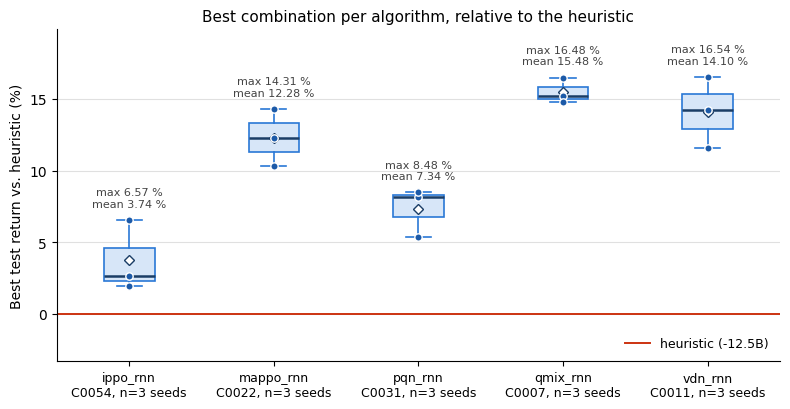

In [9]:
BOX_FILL = "#d7e6f8"
BOX_EDGE = "#2a78d6"
POINT_COLOR = "#1c5aa8"
HEURISTIC_LINE_COLOR = "#cc3311"

labels, rel_perfs = [], []
for alg, alg_combos in top_combos_by_alg.items():
    best_combo = alg_combos.loc[1, "combo_id"]
    seed_returns = runs_df.query("alg == @alg and combo_id == @best_combo")[
        "best_test_return"
    ]
    rel = (seed_returns - HEURISTIC_BASELINE) / abs(HEURISTIC_BASELINE) * 100
    rel_perfs.append(rel.to_numpy())
    labels.append(f"{alg}\n{best_combo}, n={len(rel)} seeds")

fig, ax = plt.subplots(figsize=(1.4 * len(rel_perfs) + 1.0, 4.2))
positions = np.arange(1, len(rel_perfs) + 1)
bp = ax.boxplot(
    rel_perfs,
    positions=positions,
    widths=0.35,
    patch_artist=True,
    medianprops={"color": "#1a3d66", "linewidth": 1.8},
    whiskerprops={"color": BOX_EDGE, "linewidth": 1.2},
    capprops={"color": BOX_EDGE, "linewidth": 1.2},
    flierprops={"marker": "o", "markerfacecolor": "none", "markeredgecolor": BOX_EDGE},
    showmeans=True,
    meanprops={
        "marker": "D",
        "markersize": 5,
        "markerfacecolor": "white",
        "markeredgecolor": "#1a3d66",
    },
)
for box in bp["boxes"]:
    box.set(facecolor=BOX_FILL, edgecolor=BOX_EDGE, linewidth=1.2)

for pos, rel in zip(positions, rel_perfs):
    ax.scatter(
        np.full(len(rel), pos),
        rel,
        s=28,
        color=POINT_COLOR,
        edgecolors="white",
        linewidths=1.0,
        zorder=3,
    )
    ax.annotate(
        f"max {rel.max():.2f} %\nmean {rel.mean():.2f} %",
        xy=(pos, rel.max()),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=8,
        color="#444444",
    )

ax.axhline(
    0,
    color=HEURISTIC_LINE_COLOR,
    linewidth=1.4,
    label=f"heuristic ({HEURISTIC_BASELINE / 1e9:.1f}B)",
)
ax.margins(y=0.2)  # headroom for the annotations
ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("Best test return vs. heuristic (%)")
ax.set_title("Best combination per algorithm, relative to the heuristic", fontsize=11)
ax.yaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.legend(fontsize=9, loc="lower right", frameon=False)
fig.tight_layout()
plt.show()

## Hyperparameter sensitivity

One figure per algorithm, with one panel per swept hyperparameter (one that takes more than
one value in the algorithm's sweep). Each dot is one combination: its `best_test_return`
pooled over its seeds with `SEED_AGG`, placed (with jitter) at its value of that
hyperparameter. The black bar is the median over combinations. Flat medians mean the
hyperparameter has little marginal effect; a shifted median, or a value whose combinations
never collapse to very low returns, marks a value that matters. These are marginal views
over the whole sweep, so the effect of one hyperparameter can be masked by the others.

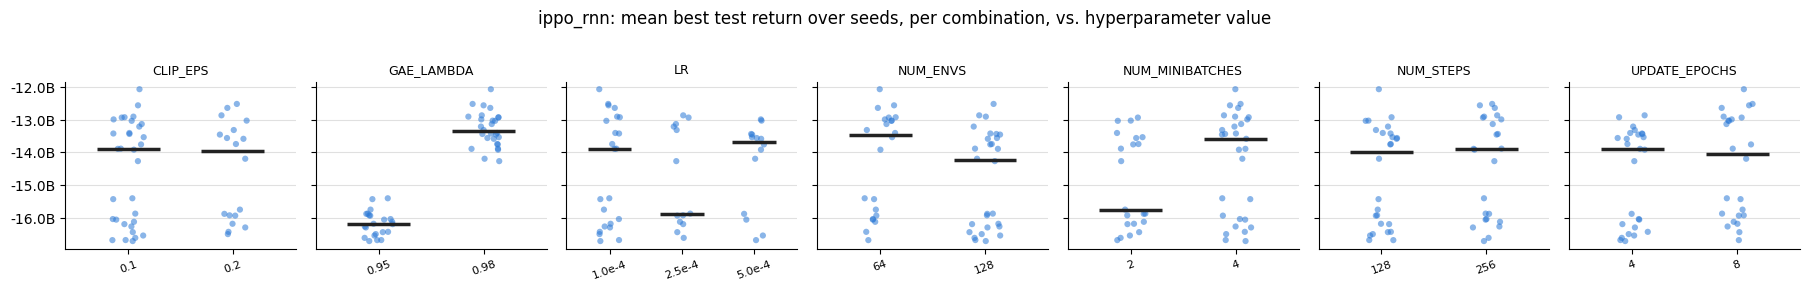

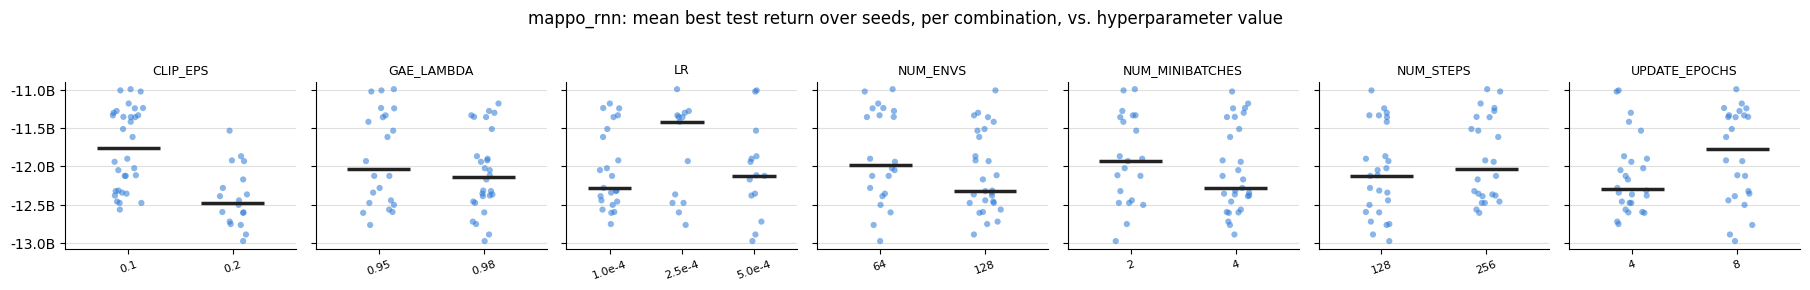

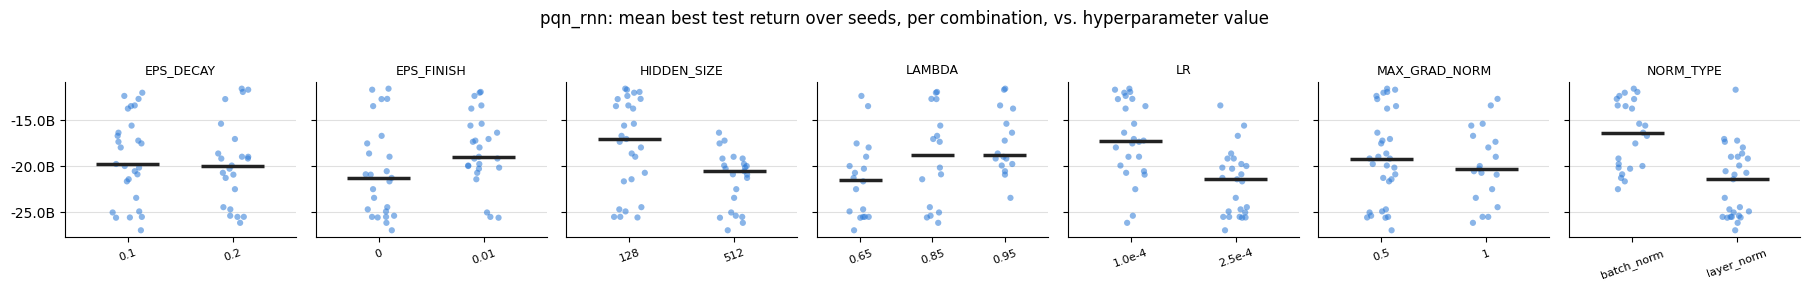

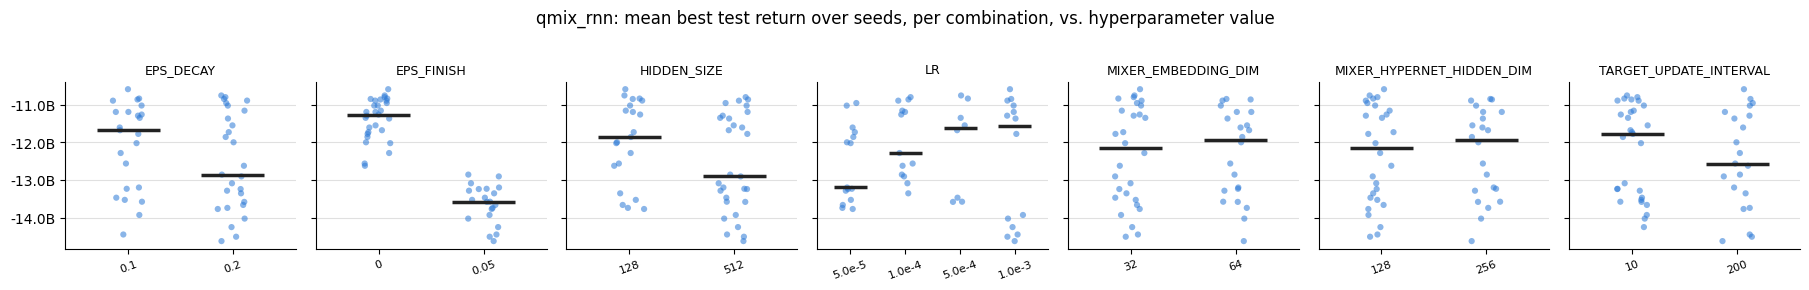

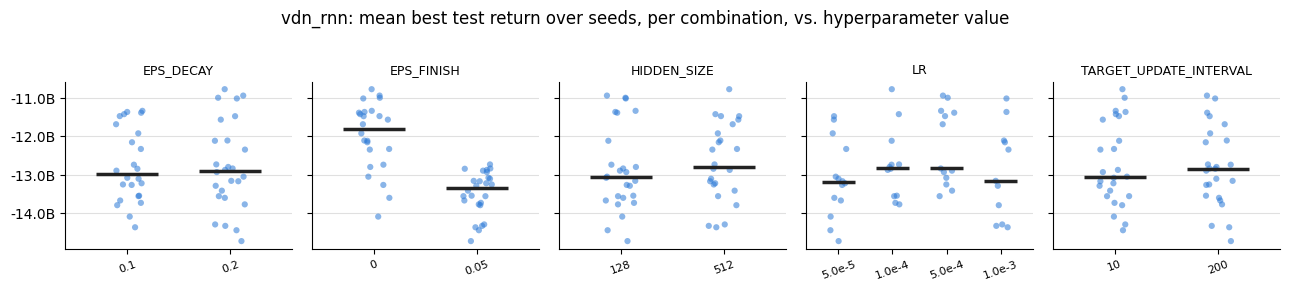

In [10]:
SEED_AGG = (
    "mean"  # how to pool best_test_return over a combination's seeds: "mean" | "median"
)

DOT_COLOR = "#2a78d6"
MEDIAN_COLOR = "#222222"
billions_formatter = FuncFormatter(lambda v, _: f"{v / 1e9:,.1f}B")
rng = np.random.default_rng(0)


def format_hp_value(v):
    if isinstance(v, (bool, np.bool_)):
        return str(v)
    if isinstance(v, (int, float, np.number)):
        if v != 0 and abs(v) < 1e-2:
            return f"{v:.1e}".replace("e-0", "e-")  # 0.0001 -> 1.0e-4
        return f"{v:g}"
    return str(v)


combo_hp_df = (
    runs_df.groupby(["alg", "combo_id"])["best_test_return"]
    .agg(SEED_AGG)
    .to_frame()
    .join(run_hyperparams.groupby(["alg", "combo_id"])[HYPERPARAMS].first())
    .reset_index()
)

for alg, alg_df in combo_hp_df.groupby("alg"):
    alg_df = alg_df.dropna(axis=1, how="all")
    swept = [c for c in HYPERPARAMS if c in alg_df and alg_df[c].nunique() > 1]
    if not swept:
        print(f"{alg}: no swept hyperparameters found")
        continue

    fig, axes = plt.subplots(
        1, len(swept), figsize=(2.6 * len(swept), 2.8), sharey=True, squeeze=False
    )
    for ax, param in zip(axes.flat, swept):
        values = sorted(alg_df[param].unique())
        for i, val in enumerate(values):
            y = alg_df.loc[alg_df[param] == val, "best_test_return"]
            ax.scatter(
                i + rng.uniform(-0.15, 0.15, len(y)),
                y,
                s=20,
                color=DOT_COLOR,
                alpha=0.55,
                edgecolors="none",
            )
            ax.hlines(
                y.median(),
                i - 0.3,
                i + 0.3,
                color=MEDIAN_COLOR,
                linewidth=2.5,
                zorder=3,
            )
        ax.set_xticks(range(len(values)))
        ax.set_xticklabels(
            [format_hp_value(v) for v in values], rotation=20, fontsize=8
        )
        ax.set_xlim(-0.6, len(values) - 0.4)
        ax.set_title(param, fontsize=9)
        ax.yaxis.set_major_formatter(billions_formatter)
        ax.yaxis.grid(True, color="#e0e0e0", linewidth=0.8)
        ax.set_axisbelow(True)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)

    fig.suptitle(
        f"{alg}: {SEED_AGG} best test return over seeds, per combination, vs. hyperparameter value",
        y=1.02,
    )
    fig.tight_layout()
    plt.show()

## Combo performance CDF

Empirical CDF over every combo of an algorithm's sweep, one curve per algorithm
in a single axes: at return `x` the curve gives the fraction of that algorithm's
combos whose seed-pooled `best_test_return` is at most `x`. A curve sitting far
left has many combos that collapsed; a steep curve means the sweep barely moved
performance; the right-hand end is the algorithm's rank-1 combo from the tables
above. The dashed line is the heuristic baseline, so the part of a curve to its
right is the share of the sweep that beat the heuristic — tabulated under the
plot, together with each sweep's median and best combo.

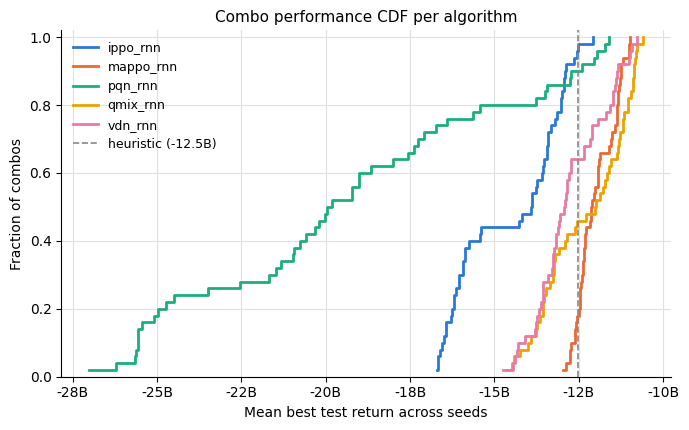

,n_combos,median_return_B,best_return_B,pct_above_heuristic
alg,,,,
ippo_rnn,50,-13.90,-12.07,4.0
mappo_rnn,50,-12.12,-10.99,82.0
pqn_rnn,50,-19.89,-11.61,10.0
qmix_rnn,50,-12.01,-10.59,54.0
vdn_rnn,50,-12.92,-10.77,36.0


In [11]:
# Needs only `runs_df` and HEURISTIC_BASELINE from the cells above
CDF_SEED_AGG = "mean"  # pool best_test_return across a combo's seeds: "mean" | "median"
CDF_BASELINE = HEURISTIC_BASELINE  # heuristic baseline return, as in the plots above

# Fixed hue per algorithm, assigned by name and never by rank, so a curve keeps
# its colour when the set of algorithms changes.
ALG_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
CDF_BASELINE_COLOR = "#888888"

# One score per combo
combo_scores = (
    runs_df.groupby(["alg", "combo_id"])["best_test_return"]
    .agg(CDF_SEED_AGG)
    .reset_index()
)
cdf_algs = sorted(combo_scores["alg"].unique())
alg_color = {alg: ALG_COLORS[i % len(ALG_COLORS)] for i, alg in enumerate(cdf_algs)}

fig, ax = plt.subplots(figsize=(7.0, 4.4))

summary_rows = []
for alg in cdf_algs:
    scores = np.sort(
        combo_scores.loc[combo_scores["alg"] == alg, "best_test_return"].to_numpy()
    )
    cdf = np.arange(1, len(scores) + 1) / len(scores)
    ax.step(scores, cdf, where="post", color=alg_color[alg], linewidth=2, label=alg)
    summary_rows.append(
        {
            "alg": alg,
            "n_combos": len(scores),
            "median_return_B": np.median(scores) / 1e9,
            "best_return_B": scores[-1] / 1e9,
            "pct_above_heuristic": (scores > CDF_BASELINE).mean() * 100,
        }
    )

ax.axvline(
    CDF_BASELINE,
    color=CDF_BASELINE_COLOR,
    linestyle="--",
    linewidth=1.2,
    label=f"heuristic ({CDF_BASELINE / 1e9:.1f}B)",
)

ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1e9:,.0f}B"))
ax.set_xlabel(f"{CDF_SEED_AGG.title()} best test return across seeds")
ax.set_ylabel("Fraction of combos")
ax.set_ylim(0, 1.02)
ax.set_title("Combo performance CDF per algorithm", fontsize=11)
ax.grid(True, color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.legend(fontsize=9, loc="upper left", frameon=False)

fig.tight_layout()
plt.show()

display(pd.DataFrame(summary_rows).set_index("alg").round(2))